# 02 · Week 1 results: baseline models on MovieLens-1M

Five models evaluated under the shared protocol (Methodology, Chapter 7):
- per-user chronological split
- full-catalog ranking
- fit on train → early-stop on validation → refit on train + validation → test once

**The hyperparameters are literature defaults, not tuned yet.** Every model gets the same Optuna
tuning budget in Week 3, so these are first results, not final conclusions.

Reproduce from `ml/`: `uv run recsys benchmark -c ml-1m`, then run this notebook.

In [1]:
import pandas as pd
from IPython.display import Image, display

from recsys.analysis import results as R
from recsys.experiments.config import ExperimentConfig
from recsys.experiments.report import DISPLAY_NAMES
from recsys.paths import figures_dir, results_docs_dir

cfg = ExperimentConfig.load("ml-1m")
MODELS = list(cfg.models)
FIG = figures_dir("results", "ml-1m")
test = pd.read_csv(results_docs_dir("ml-1m", "week1_baselines", "test.csv"))
per_user = R.load_per_user("ml-1m", cfg.split.name, MODELS)


def show(path) -> None:
    display(Image(filename=str(path), width=900))

## 1. Main results (test set)

In [2]:
test.set_index("model").round(4)

,NDCG@10,Recall@10,HR@10,P@10,MRR@10,MAP@10,NDCG@20,Recall@20,Coverage@10,Novelty@10,ILD@10,ARP@10,fit (s)
model,,,,,,,,,,,,,
MostPop,0.0466,0.0445,0.2322,0.0350,0.0893,0.0213,0.0570,0.0788,0.0298,1.5664,0.7750,2060.9696,0.0007
UserKNN,0.0727,0.0772,0.3182,0.0477,0.1272,0.0366,0.0906,0.1352,0.1342,2.0974,0.7536,1541.9503,0.0058
ItemKNN,0.0709,0.0790,0.3270,0.0474,0.1223,0.0345,0.0888,0.1346,0.2869,2.4784,0.7140,1270.5994,1.0224
EASE,0.0810,0.0936,0.3629,0.0519,0.1368,0.0399,0.1025,0.1604,0.2331,2.5026,0.7480,1234.0770,2.5159
BPR-MF,0.0685,0.0751,0.3230,0.0459,0.1224,0.0327,0.0860,0.1296,0.4130,2.7305,0.7155,1147.6421,125.7536


**Findings**
- **EASE is the most accurate model on every accuracy metric:** NDCG@10 0.0810 and HR@10 36.3%. For
  about a third of users, at least one of the 10 recommended movies is one they actually liked next.
- **The simple neighbourhood methods beat the learned factorization model at default settings:**
  UserKNN 0.0727 and ItemKNN 0.0709 vs BPR-MF 0.0685. This echoes the reproducibility debate
  (Ferrari Dacrema et al., 2019; Rendle et al., 2020). Week 3 tuning will show whether it holds.
- **Personalization clearly pays off:** EASE improves NDCG@10 over MostPop by 74%.
- **The absolute numbers look low compared with many papers.** Predicting each user's *future* likes,
  ranked against the full catalog, is much harder than the random hold-out with ~100 sampled
  candidates that is common in the literature.

## 2. Are the differences real? Paired significance tests

The Wilcoxon signed-rank test compares two models on **the same users** (per-user NDCG@10). Holm's
correction keeps the overall false-positive rate at 5% across the several comparisons.

In [3]:
R.paired_tests(per_user, reference="ease")

,comparison,mean difference,relative difference,users better / worse / tied,p-value,p-value (Holm),significant (p<0.05)
0,EASE vs MostPop,0.034347,0.736509,1766 / 839 / 3429,1.299488e-75,5.197950e-75,True
1,EASE vs BPR-MF,0.012437,0.181438,1482 / 1130 / 3422,1.047468e-15,3.142403e-15,True
2,EASE vs ItemKNN,0.010036,0.141462,1393 / 1077 / 3564,2.229699e-13,4.459397e-13,True
3,EASE vs UserKNN,0.008329,0.114636,1344 / 1043 / 3647,9.045206e-12,9.045206e-12,True


In [4]:
R.paired_tests(per_user, reference="userknn")

,comparison,mean difference,relative difference,users better / worse / tied,p-value,p-value (Holm),significant (p<0.05)
0,UserKNN vs MostPop,0.026018,0.557916,1454 / 748 / 3832,2.968704e-61,1.187482e-60,True
1,UserKNN vs EASE,-0.008329,-0.102846,1043 / 1344 / 3647,9.045206e-12,2.713562e-11,True
2,UserKNN vs BPR-MF,0.004108,0.059932,1281 / 1193 / 3560,1.371238e-02,2.742476e-02,True
3,UserKNN vs ItemKNN,0.001707,0.024067,1161 / 1117 / 3756,2.201206e-01,2.201206e-01,False


In [5]:
wide = per_user.pivot_table(index="user_idx", columns="model", values="ndcg@10")
ties = pd.DataFrame(
    {
        other: {
            "tied users": int((wide["ease"] == wide[other]).sum()),
            "of which both score 0": int(((wide["ease"] == wide[other]) & (wide["ease"] == 0)).sum()),
        }
        for other in ["userknn", "itemknn", "bpr", "mostpop"]
    }
).T
print(f"Users for whom EASE finds none of their next liked movies: {(wide['ease'] == 0).mean():.1%}")
ties

Users for whom EASE finds none of their next liked movies: 63.7%


,tied users,of which both score 0
userknn,3647,3478
itemknn,3564,3429
bpr,3422,3315
mostpop,3429,3380


- **EASE beats every other model significantly** (Holm-corrected p < 10⁻¹¹). For example, it improves
  NDCG@10 by 11.5% over UserKNN.
- **UserKNN vs ItemKNN is not significant** (p = 0.22): the two neighbourhood methods are statistically
  tied.
- **Most users are "tied" in each comparison** (about 3,400–3,650 of 6,034). In 95–99% of these cases,
  *neither* model finds any of the user's next liked movies. Even EASE misses completely for 63.7% of
  users, which shows how hard it is to predict what someone will like next.

## 3. Accuracy vs. catalog coverage

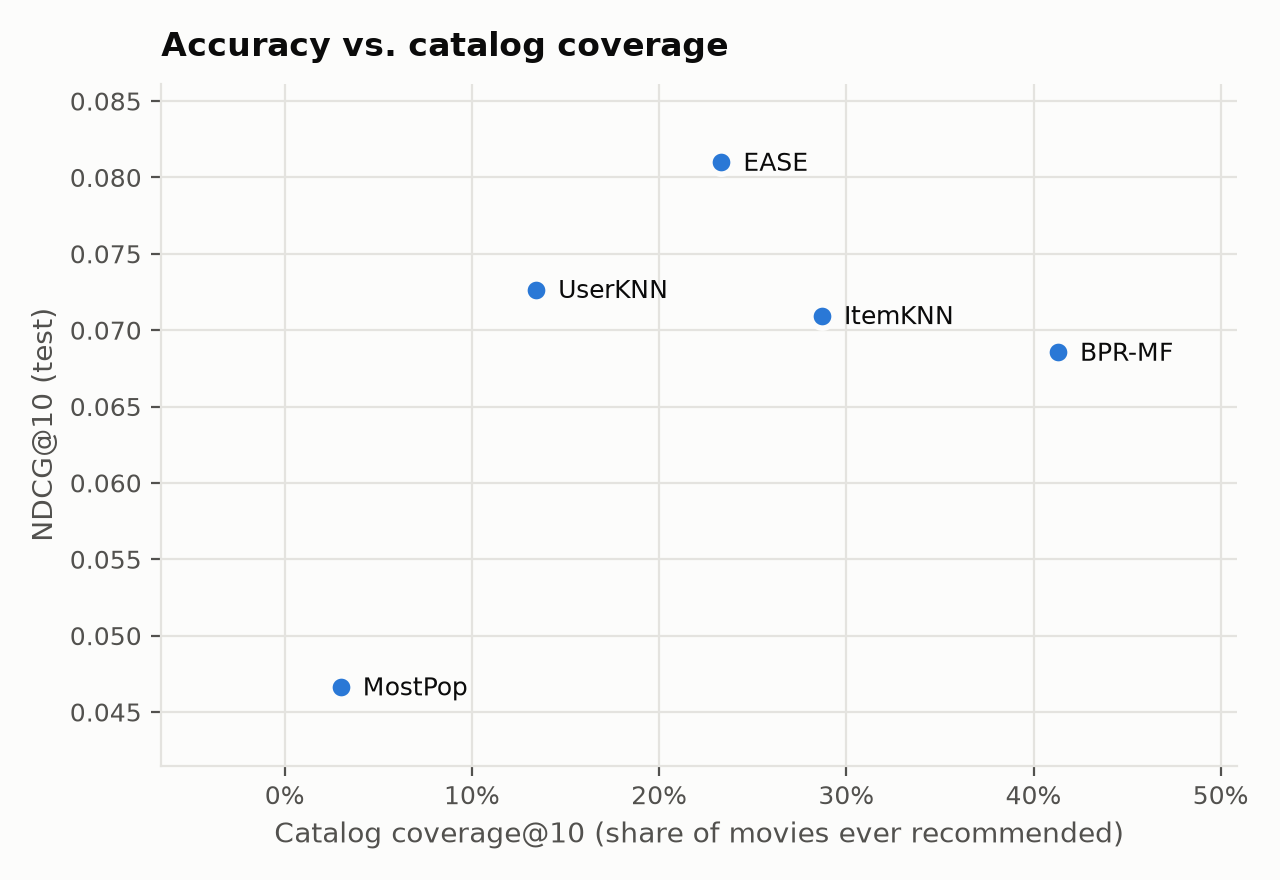

In [6]:
show(R.plot_accuracy_vs_coverage(test, FIG / "week1_accuracy_vs_coverage.png"))

- **MostPop recommends only 3% of the catalog:** everyone gets the same blockbusters.
- **BPR-MF covers the most of the catalog (41%) and has the highest novelty**, but is less accurate.
- **EASE combines the best accuracy with moderate coverage (23%).**
- **MostPop has the *highest* intra-list diversity**, because its single list mixes blockbusters from
  many genres. *Diversity within one list* and *coverage across users* measure different things,
  so the report shows both.

## 4. Who is served well? Accuracy by user activity

In [7]:
activity = R.by_activity(per_user)
targets = (
    R.add_activity_bucket(per_user[per_user["model"] == "ease"])
    .groupby("bucket", observed=False)["n_targets"]
    .median()
    .rename("median test items")
)
activity.rename(columns=DISPLAY_NAMES).join(targets).round(4)

,BPR-MF,EASE,ItemKNN,MostPop,UserKNN,users,median test items
bucket,,,,,,,
1-20,0.0760,0.1015,0.0789,0.0323,0.0857,1138,2.0
21-50,0.0630,0.0829,0.0706,0.0360,0.0662,1816,4.0
51-200,0.0594,0.0622,0.0577,0.0484,0.0600,2460,10.0
>200,0.1076,0.1124,0.1097,0.0969,0.1177,620,30.0


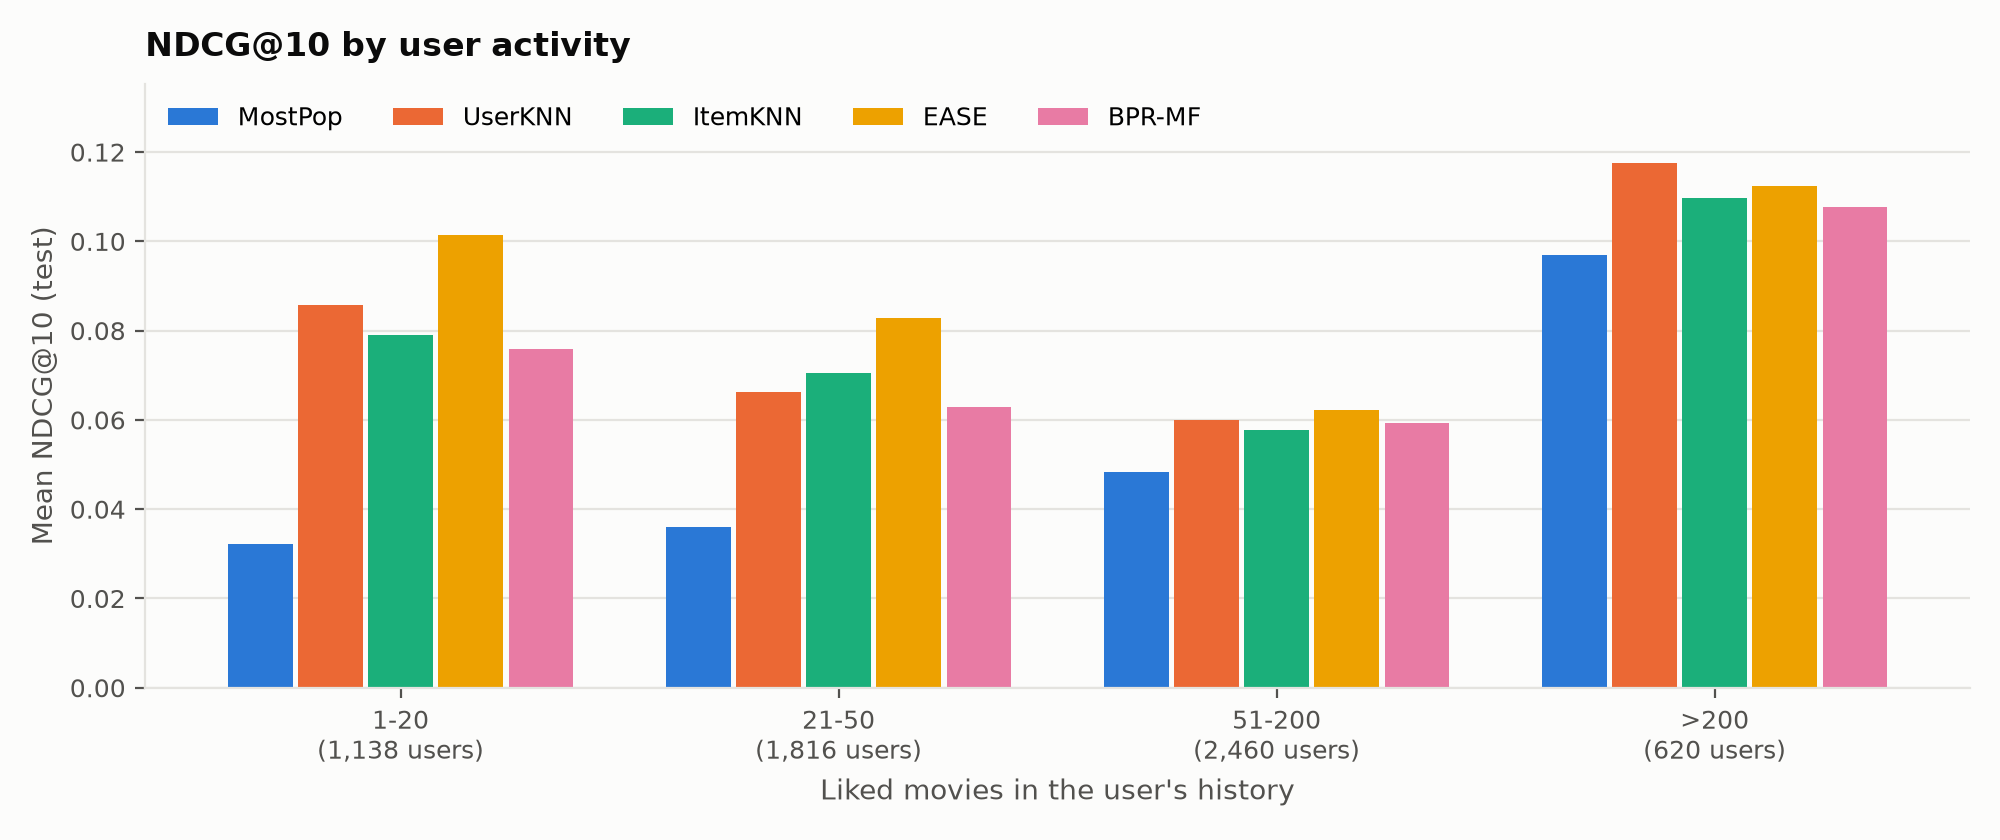

In [8]:
show(R.plot_by_activity(activity, MODELS, FIG / "week1_ndcg_by_activity.png"))

- **Compare models within a group, not groups with each other.** Users with short histories also have
  very few test items (median 2, against 30 for the most active users), and NDCG behaves differently
  with so few targets. That is why the bars are not monotone across groups.
- **EASE leads by the widest margin for users with short histories:** +18% over the next-best model for
  1–20 liked movies, and +17% for 21–50. Its lead shrinks to +4% for 51–200.
- **For the most active users (>200 liked movies), UserKNN is best** (0.1177 vs 0.1124 for EASE).
- **Different models win for different users.** This directly motivates the hybrid ranker in Week 3,
  which can learn when to trust which model, using user activity as an input feature.

## 5. BPR-MF training curve

C:\Users\aravind reddy\projects\movie-recommendation\ml\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


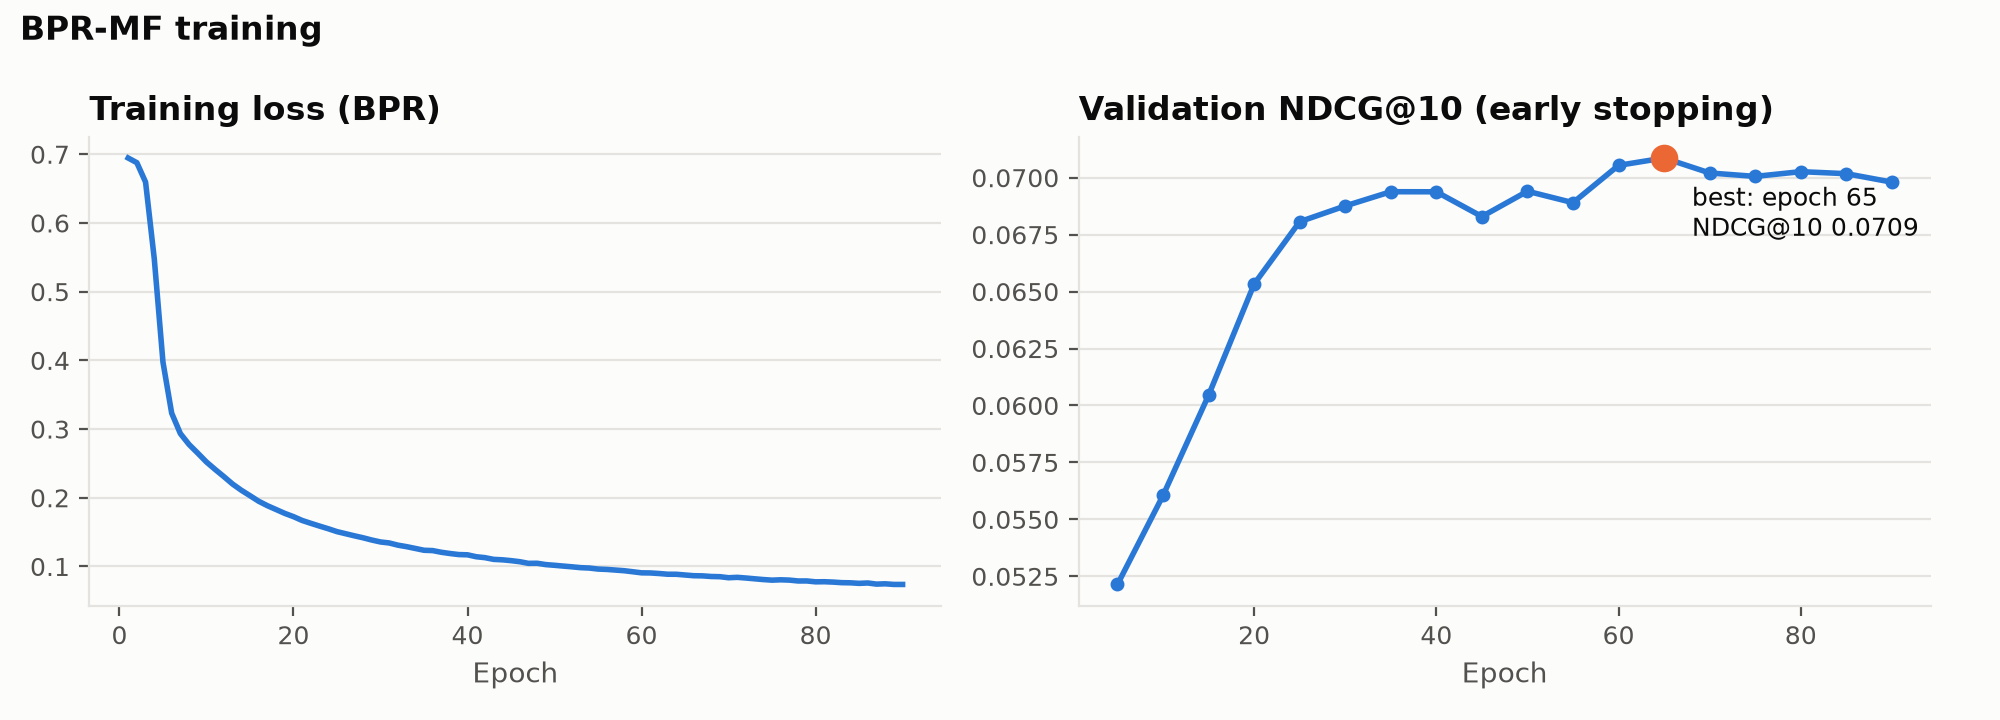

In [9]:
curve = R.load_curve_from_mlflow("ml-1m", "bpr")
show(R.plot_training_curve(curve, FIG / "week1_bpr_training_curve.png"))

**The training loss keeps falling, but validation NDCG@10 stops improving.** It plateaus at about 0.070
from epoch 25, peaks at epoch 65, and early stopping ends training at epoch 90. The model keeps fitting
its training objective without generalizing further, which suggests that regularization and learning
rate need tuning (Week 3).

## Summary for the report

| Question | Week 1 answer (untuned defaults) |
|---|---|
| Most accurate model | EASE, significantly better than every other model |
| Do learned latent factors beat neighbourhood methods? | Not at default settings (BPR-MF < UserKNN ≈ ItemKNN) |
| Is personalization worth it? | Yes: EASE improves NDCG@10 by 74% over MostPop |
| Popularity bias | MostPop covers 3% of the catalog; BPR-MF covers 41% |
| Which users gain most from EASE? | Users with short histories (+17–18% over the next-best model) |
| Is one model best for everyone? | No: UserKNN wins for the most active users, which motivates the hybrid |